# Exercise 9: NetworkX Tutorial

This notebook introduces **NetworkX**, a Python library for building and analyzing graphs (networks).


### Setup
You need: `networkx`

If needed:
```bash
pip install networkx 
```

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

print(nx.__version__)

3.7


## Graph basics: nodes and edges

A **graph** is a mathematical object made of:
- **Nodes** (aka vertices)
- **Edges** (connections between nodes)

Formally, Nodes are elements of a set, $V$, while edges are a subset of the set product of $V$ with itself. We typically call the resulting graph $G$.

- $V = \{v_1,v_2, \dots, v_n\}$
- $E \subseteq V \times V$ 
- $G = (V,E)$

### Networks 
A **network** is distinct a graph that represents real-world data or phenomenon. I.e., it is a graph with some semantic meaning attached to the vertices and edges. 

- Nodes = people, edges = friendships → social network
- Nodes = cities, edges = roads → transportation network
- Nodes = proteins, edges = interactions → biological network

In practice, the terms graph and network are often used interchangeably, though network usually emphasizes an applied or empirical context.
**Network analysis** is a distinct area within data science and applied mathematics.  
While many real-world systems can be naturally represented as networks, historically:

- Supervised learning methods were difficult to apply directly to relational data
- - Changes is node/edge ordering will change analysis; computing a ''canonical form'' is an open problem
- - - This is closely related to the graph isomorphism problem, which is neither known to be NP-complete nor known to admit a polynomial-time algorithm
- - There are no features to learn, the data is more abstract
- - Size of structure is variable; be it the number of nodes or size of subgraph

- Statistical modeling of networks lagged behind tabular data until the mid-to-late 1990s
- - We needed stronger theory on small world networks, exponential random graphs, and later graph embeddings
- - Now, GNNs are very popular

This has changed substantially in recent years with advances in computation and methodology.


### NetworkX

In this course, we will use **NetworkX**, a Python library for creating, manipulating, and analyzing graphs and networks. Its main advantages are:
- Simple API
- Documentation
- Well-suited for teaching, prototyping, and exploratory analysis

NetworkX prioritizes clarity and flexibility over speed. For very large graphs or performance-critical applications, other Python libraries (e.g., `graph-tool`) may be more appropriate.

NetworkX supports several graph types:

- `nx.Graph()` – undirected graphs  
- `nx.DiGraph()` – directed graphs  
- `nx.MultiGraph()` – undirected graphs with parallel edges  
- `nx.MultiDiGraph()` – directed graphs with parallel edges  

We will mostly focus on general undirected graphs, though there are good use cases for DiGraphs and MultiGraphs.


In [2]:
G = nx.Graph()

# Add nodes
G.add_node("Alice")
G.add_nodes_from(["Bob", "Charlie", "Dina"])

# Add edges
G.add_edge("Alice", "Bob")
G.add_edges_from([
    ("Bob", "Charlie"),
    ("Charlie", "Dina"),
    ("Alice", "Dina"), 
    ("Dina", "Carlos") #Notice Carlos is not yet a node
])

print("Nodes:", list(G.nodes))
print("Edges:", list(G.edges))
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Nodes: ['Alice', 'Bob', 'Charlie', 'Dina', 'Carlos']
Edges: [('Alice', 'Bob'), ('Alice', 'Dina'), ('Bob', 'Charlie'), ('Charlie', 'Dina'), ('Dina', 'Carlos')]
Number of nodes: 5
Number of edges: 5


Graphs in NetworkX rely heavily on *dictionaries*. Each vertex is basically a dictionary with a list of properties, and maintains an adjacency list as well.

In [3]:
for n in G.nodes:
    print(n, "->", list(G.neighbors(n)))

Alice -> ['Bob', 'Dina']
Bob -> ['Alice', 'Charlie']
Charlie -> ['Bob', 'Dina']
Dina -> ['Charlie', 'Alice', 'Carlos']
Carlos -> ['Dina']


We can see this is a dictionary using dict-like indexing. Note that AtlasView is a special property that indicates the node/edge object is read-only. 

In [4]:
G['Alice']


AtlasView({'Bob': {}, 'Dina': {}})

In [5]:
G['Alice']['Bob']

{}

In [6]:
G['Alice']['Charlie']

KeyError: 'Charlie'

Each node/edge object can contain additional attributes, but to modify them, you must access the objects properly.

In [7]:
G.nodes()['Alice']['birthday'] = "April"

G.nodes()['Alice']

{'birthday': 'April'}

Of course, adding nodes, edges, and attributes can all be done programmatically. 

In [8]:
for v in G.nodes():
    print(v)
    G.nodes()[v]['person'] = True

Alice
Bob
Charlie
Dina
Carlos


In [9]:
#Alternative (nicer) syntax
for v, data in G.nodes(data=True):
    print(v)
    data['person'] = True

Alice
Bob
Charlie
Dina
Carlos


In [10]:
first_names = [
    "Alice",
    "Jamal",
    "Priya",
    "Luca",
    "Sofia",
    "Daniel",
    "Fatima",
    "Noah",
    "Mei",
    "Carlos",
    "Aisha",
    "Tomas",
    "Elena",
    "Marcus",
    "Yuki",
    "Rohan",
    "Isabelle",
    "Ahmed",
    "Hannah",
    "Diego"
]

In [11]:
for name in first_names: 
    G.add_node(name)

#Or, if vertices already in a list
G.add_nodes_from(first_names)


In [12]:
new_edges = [('Alice', 'Bob'), ('Alice', 'Dina'), ('Bob', 'Charlie'), ('Charlie', 'Dina'), ('Dina', 'Carlos')]
G.add_edges_from(new_edges)

In [13]:
G.nodes()

NodeView(('Alice', 'Bob', 'Charlie', 'Dina', 'Carlos', 'Jamal', 'Priya', 'Luca', 'Sofia', 'Daniel', 'Fatima', 'Noah', 'Mei', 'Aisha', 'Tomas', 'Elena', 'Marcus', 'Yuki', 'Rohan', 'Isabelle', 'Ahmed', 'Hannah', 'Diego'))

### Task 1 
- Create a new graph, G (erasing the above graph in memory)
- Add the people's names (from the `first_names` list) as nodes to the graph
- Connect two people with an edge if their names share a letter
- Report the number of nodes and edges in this graph. What can you reason about, if anything, this graph's structure? 

In [14]:
from itertools import combinations

G = nx.Graph()
G.add_nodes_from(first_names)

# edge if the two names have at least one letter in common (case-insensitive);
# store how many distinct letters they share as edge weight
letters = {name: set(name.lower()) for name in first_names}
for a, b in combinations(first_names, 2):
    common = letters[a] & letters[b]
    if common:
        G.add_edge(a, b, weight=len(common))

n, m = G.number_of_nodes(), G.number_of_edges()
print(f"nodes = {n}, edges = {m} (complete graph would have {n*(n-1)//2})")
print(f"density = {nx.density(G):.2f}, average clustering = {nx.average_clustering(G):.2f}")
print(f"connected = {nx.is_connected(G)}, diameter = {nx.diameter(G)}")
print("degree per name:", dict(sorted(G.degree, key=lambda x: x[1])))

nodes = 20, edges = 173 (complete graph would have 190)
density = 0.91, average clustering = 0.93
connected = True, diameter = 2
degree per name: {'Yuki': 11, 'Mei': 14, 'Diego': 15, 'Hannah': 16, 'Jamal': 17, 'Luca': 17, 'Noah': 17, 'Carlos': 17, 'Rohan': 17, 'Tomas': 18, 'Elena': 18, 'Marcus': 18, 'Ahmed': 18, 'Alice': 19, 'Priya': 19, 'Sofia': 19, 'Daniel': 19, 'Fatima': 19, 'Aisha': 19, 'Isabelle': 19}


{'a': '17/20', 'i': '10/20', 'e': '7/20', 'l': '7/20', 'm': '6/20', 's': '6/20'}

with >= 2 shared letters: edges = 103, density = 0.54


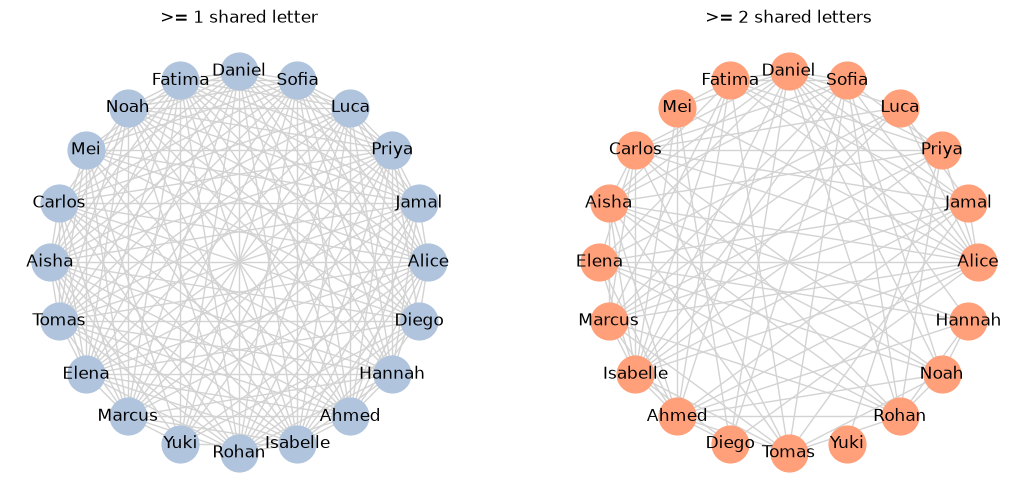

In [15]:
# Which letters are responsible? Fraction of names that contain each letter
from collections import Counter
letter_freq = Counter(l for s in letters.values() for l in s)
print({l: f"{c}/{n}" for l, c in letter_freq.most_common(6)})

# A stricter rule for comparison: at least 2 shared letters
G2 = nx.Graph([(u, v) for u, v, w in G.edges(data="weight") if w >= 2])
G2.add_nodes_from(first_names)
print(f"\nwith >= 2 shared letters: edges = {G2.number_of_edges()}, density = {nx.density(G2):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
nx.draw(G, nx.circular_layout(G), ax=ax[0], with_labels=True, node_size=700, node_color="lightsteelblue", edge_color="lightgray")
ax[0].set_title(">= 1 shared letter")
nx.draw(G2, nx.circular_layout(G2), ax=ax[1], with_labels=True, node_size=700, node_color="lightsalmon", edge_color="lightgray")
ax[1].set_title(">= 2 shared letters")
plt.show()

**Answer (Task 1).** The graph has **20 nodes and 173 edges**, out of 190 possible ones. That gives a density of 0.91, an average clustering coefficient of 0.93 and a diameter of 2. The graph is therefore **almost complete**: every name is connected to at least 11 others, and any two names are at most two steps apart.

The reason is the letter statistics, not the people. The letter *a* appears in 17 of the 20 names and *i* in 10, so most pairs share a vowel. The few missing edges involve short names without an *a*, such as **Yuki** (degree 11), **Mei** (14) and **Diego** (15). Requiring at least 2 shared letters already drops the density to about 0.54. Conclusion: "shares a letter" produces a dense, almost structureless graph. A useful network needs a more selective rule for creating edges.

## Drawing graphs

NetworkX uses Matplotlib for drawing. However, there are some easy shortcuts.

The drawing routines are seperate from the layout routines. This is a design decision in case you want finer control over the layout. 

A layout is an assignment of coordinates to the vertices of the graph (edges are drawn as straight-line segments between them).
There are many layouts built in to the library, for instance:
- `spring_layout` 
- `circular_layout`
- `kamada_kawai_layout`
- `shell_layout`

Note: NetworkX is **not**, a visualization library. GraphViz is an excellent open source graph drawing library with nice Python bindings (also available within NetworkX).

In [16]:
G = nx.Graph()

# Add nodes
G.add_node("Alice")
G.add_nodes_from(["Bob", "Charlie", "Dina"])

# Add edges
G.add_edge("Alice", "Bob")
G.add_edges_from([
    ("Bob", "Charlie"),
    ("Charlie", "Dina"),
    ("Alice", "Dina"), 
    ("Dina", "Carlos") #Notice Carlos is not yet a node
])

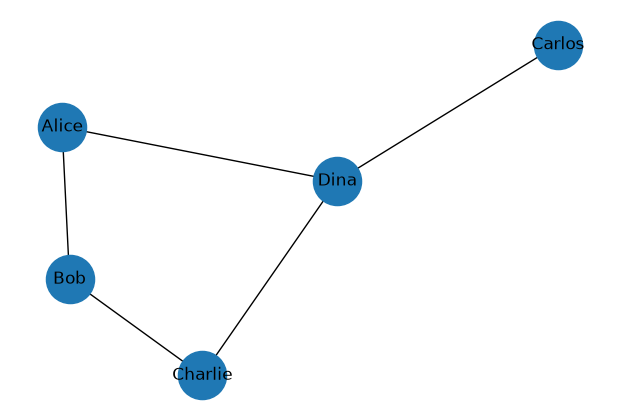

In [17]:
plt.figure(figsize=(6, 4))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_size=1200)
plt.show()

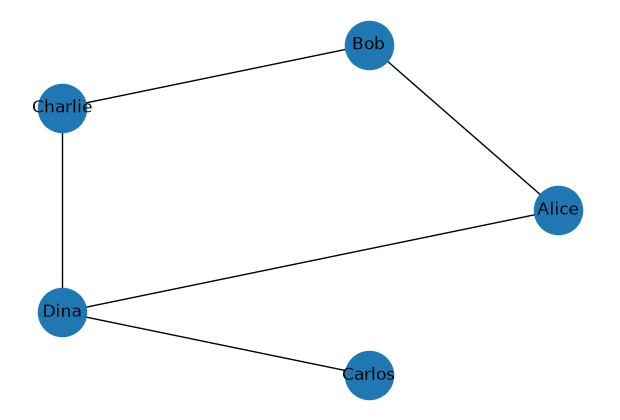

In [18]:
plt.figure(figsize=(6, 4))
pos = nx.circular_layout(G)
nx.draw(G, pos, with_labels=True, node_size=1200)
plt.show()

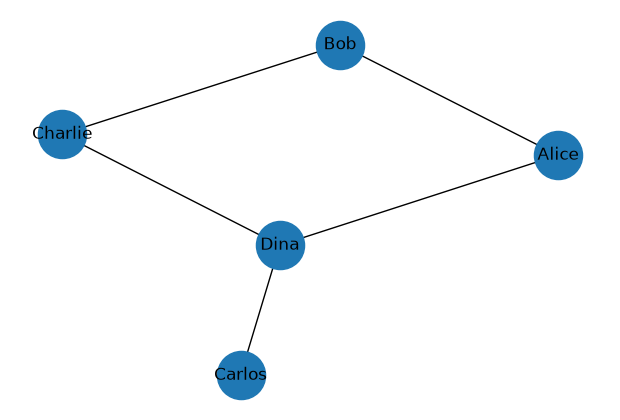

In [19]:
plt.figure(figsize=(6, 4))
pos = nx.kamada_kawai_layout(G)
nx.draw(G, pos, with_labels=True, node_size=1200)
plt.show()

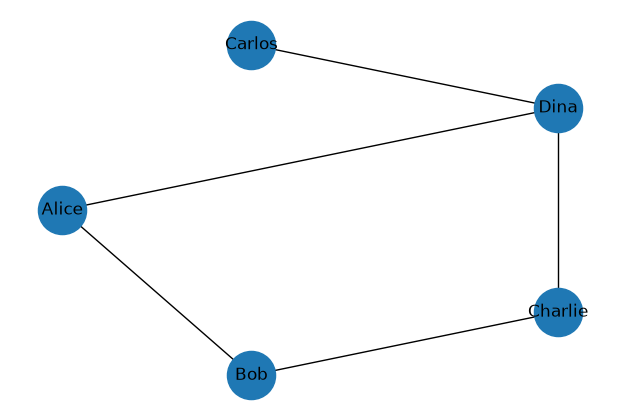

In [20]:
plt.figure(figsize=(6, 4))
pos = nx.shell_layout(G)
nx.draw(G, pos, with_labels=True, node_size=1200)
plt.show()

Each of the NetworkX layout algorithms return a dictionary of numpy arrays (length 2) for the x and y positions. 

In [21]:
pos

{'Alice': array([-1.00000000e+00, -8.74227766e-08]),
 'Bob': array([-0.30901712, -0.95105648]),
 'Charlie': array([ 0.80901724, -0.58778495]),
 'Dina': array([0.809017  , 0.58778524]),
 'Carlos': array([-0.30901742,  0.95105636])}

Network layout is a conceptually simple but technically deep field. Many popular algorithms focus on physical principles, modeling the vertices as particles and edges as springs. Particles repel each other, while springs have a desired length. Simulating this system results in a low-energy configuration which tends to be aesthetically pleasing. 

# Task 2: Visualization 
Finding the right layout algorithm for your graph to get some conceptual understanding of the data is often an iterative process. 
- Load the edge list in sierpinski.txt. You may need to open the file to understand its structure, but is simply a list of edges. 
- Try to guess what the structure of the graph looks like from the list
- Try several layout algorithms to see which gives you good results

In [22]:
# sierpinski.txt was NOT included in the ex4.zip we received.
# Fallback: build a Sierpinski gasket graph recursively (three copies of the previous level,
# glued at their corners) and write it as an edge list "u v" -- same format as the task file.
# If the original sierpinski.txt is put next to this notebook, it is used instead.
from pathlib import Path

def sierpinski_graph(level):
    """Return (graph, corners). Level 0 = a single triangle."""
    if level == 0:
        return nx.cycle_graph(3), (0, 1, 2)
    H, (a, b, c) = sierpinski_graph(level - 1)
    size = H.number_of_nodes()
    # three shifted copies of the previous level
    G = nx.disjoint_union_all([H, H, H])
    top, left, right = 0, size, 2 * size
    # glue: top.b = left.a, top.c = right.a, left.c = right.b
    for keep, drop in [(top + b, left + a), (top + c, right + a), (left + c, right + b)]:
        G = nx.contracted_nodes(G, keep, drop, self_loops=False)
    G = nx.convert_node_labels_to_integers(G, label_attribute="old")
    old_to_new = {d["old"]: v for v, d in G.nodes(data=True)}
    corners = (old_to_new[top + a], old_to_new[left + b], old_to_new[right + c])
    for v in G:
        del G.nodes[v]["old"]
        G.nodes[v].pop("contraction", None)
    return G, corners

path = Path("sierpinski.txt")
if not path.exists():
    gen, _ = sierpinski_graph(4)
    nx.write_edgelist(gen, path, data=False)
    print("sierpinski.txt missing -> generated a level-4 Sierpinski gasket")

print(path.read_text().splitlines()[:8], "...")
S = nx.read_edgelist(path, nodetype=int)

sierpinski.txt missing -> generated a level-4 Sierpinski gasket
['0 1', '0 2', '1 2', '1 3', '1 4', '2 5', '2 4', '3 4'] ...


In [23]:
# Looking at the edge list before drawing: basic statistics give a strong hint
deg_count = Counter(d for _, d in S.degree)
print("nodes:", S.number_of_nodes(), " edges:", S.number_of_edges())
print("degree counts:", dict(deg_count))
print("triangles:", sum(nx.triangles(S).values()) // 3)
print("planar:", nx.check_planarity(S)[0], " diameter:", nx.diameter(S))

nodes: 123  edges: 243
degree counts: {2: 3, 4: 120}
triangles: 108
planar: True  diameter: 16


**Guess:** Almost all vertices have degree 4, and exactly three have degree 2. Those three must be the outer corners. The graph is planar, full of triangles, and has a large diameter compared with its size. This fits a **Sierpinski triangle**: a triangle that is recursively divided into three corner triangles, where neighbouring sub-triangles meet in one shared vertex (degree 4).

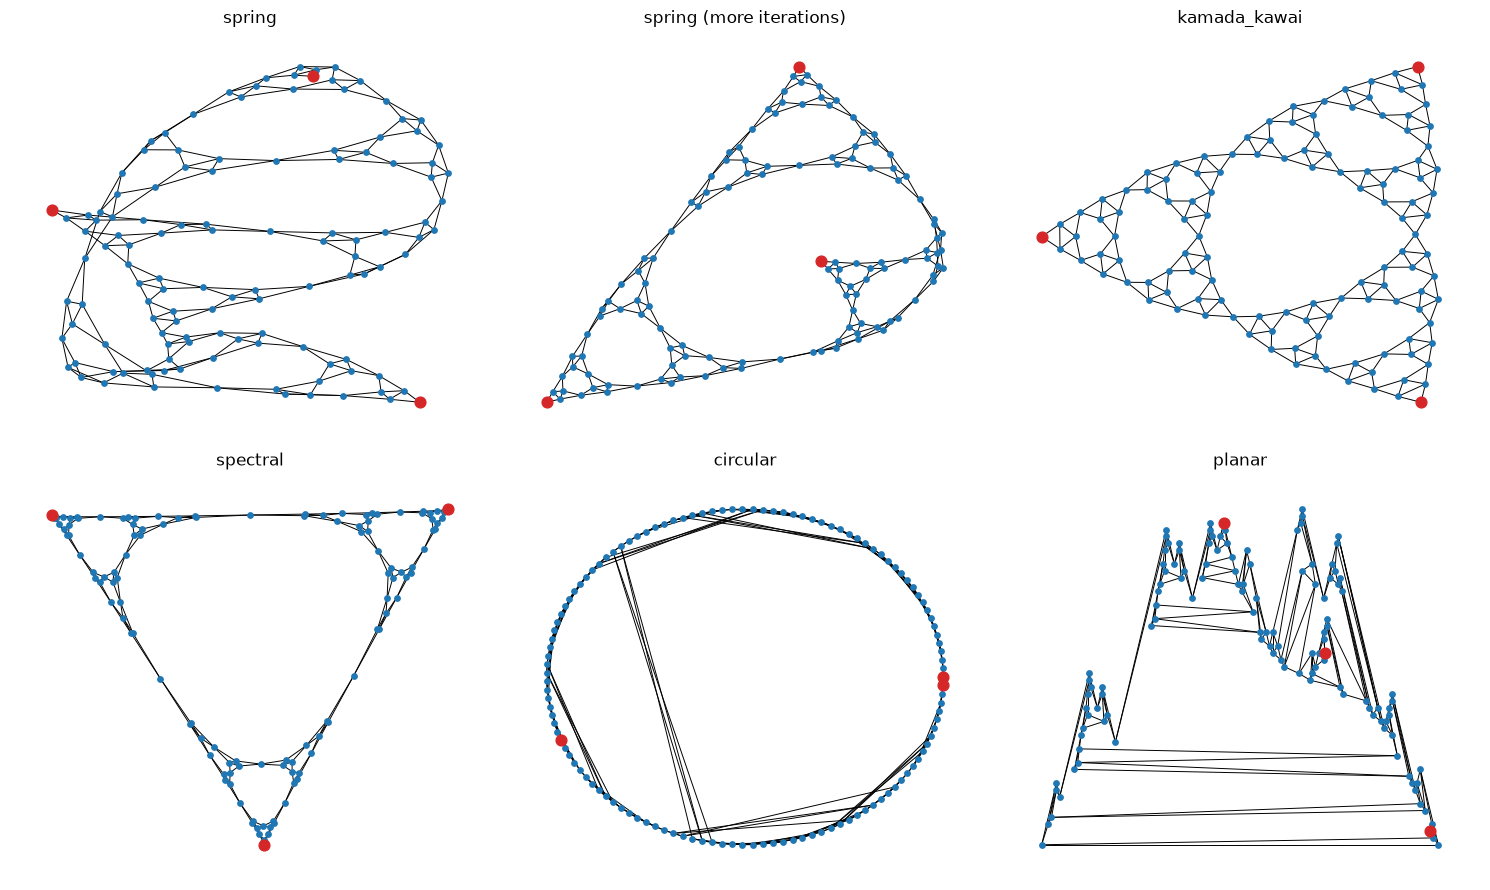

In [24]:
layout_funcs = {
    "spring": lambda g: nx.spring_layout(g, seed=1),
    "spring (more iterations)": lambda g: nx.spring_layout(g, seed=1, iterations=500),
    "kamada_kawai": nx.kamada_kawai_layout,
    "spectral": nx.spectral_layout,
    "circular": nx.circular_layout,
    "planar": nx.planar_layout,
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, f) in zip(axes.ravel(), layout_funcs.items()):
    corners = [v for v, d in S.degree if d == 2]
    pos = f(S)
    nx.draw(S, pos, ax=ax, node_size=15, width=0.7, node_color="tab:blue")
    nx.draw_networkx_nodes(S, pos, nodelist=corners, ax=ax, node_size=60, node_color="tab:red")
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Result:** The three corner vertices are marked in red. **`kamada_kawai`** reproduces the Sierpinski triangle almost perfectly, because it places vertices so that Euclidean distances match shortest-path distances. That works well for a regular graph with a large diameter. `spring` often gets stuck in a twisted configuration, and more iterations only partly help. `spectral` shows the outer triangle but squeezes the inner levels together. `circular` throws away all the structure. `planar` guarantees no crossings, but produces long, distorted edges. Conclusion: for "geometric", mesh-like graphs, distance-based layouts such as Kamada–Kawai work best.

## Simple analysis: Degrees

The degree of a vertex in a graph is the number of incident edges (i.e. the number of neighbors). It turns out, that looking at this statistic across the graph is actually pretty informative. 


In [25]:
#This is a popular social network for analysis, a co-occurance network from the novel Les Miserable.
G = nx.read_gml("lesmis.gml")

In [26]:
degree = nx.degree(G)
for deg in degree: 
    print(deg)

('Myriel', 10)
('Napoleon', 1)
('MlleBaptistine', 3)
('MmeMagloire', 3)
('CountessDeLo', 1)
('Geborand', 1)
('Champtercier', 1)
('Cravatte', 1)
('Count', 1)
('OldMan', 1)
('Labarre', 1)
('Valjean', 36)
('Marguerite', 2)
('MmeDeR', 1)
('Isabeau', 1)
('Gervais', 1)
('Tholomyes', 9)
('Listolier', 7)
('Fameuil', 7)
('Blacheville', 7)
('Favourite', 7)
('Dahlia', 7)
('Zephine', 7)
('Fantine', 15)
('MmeThenardier', 11)
('Thenardier', 16)
('Cosette', 11)
('Javert', 17)
('Fauchelevent', 4)
('Bamatabois', 8)
('Perpetue', 2)
('Simplice', 4)
('Scaufflaire', 1)
('Woman1', 2)
('Judge', 6)
('Champmathieu', 6)
('Brevet', 6)
('Chenildieu', 6)
('Cochepaille', 6)
('Pontmercy', 3)
('Boulatruelle', 1)
('Eponine', 11)
('Anzelma', 3)
('Woman2', 3)
('MotherInnocent', 2)
('Gribier', 1)
('Jondrette', 1)
('MmeBurgon', 2)
('Gavroche', 22)
('Gillenormand', 7)
('Magnon', 2)
('MlleGillenormand', 7)
('MmePontmercy', 2)
('MlleVaubois', 1)
('LtGillenormand', 4)
('Marius', 19)
('BaronessT', 2)
('Mabeuf', 11)
('Enjolras'

A common visualization scheme is to scale the size of a vertex based on it's degree. Let's take a look.

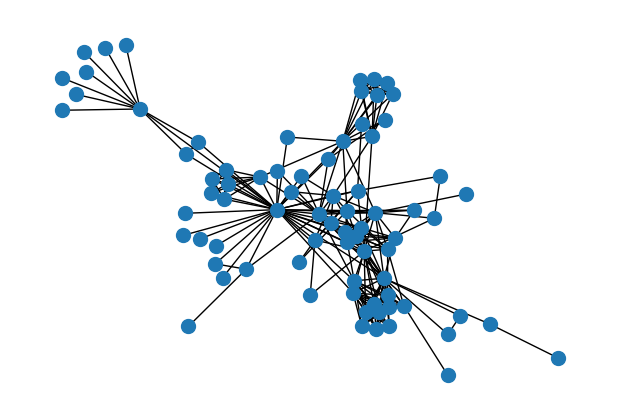

In [27]:
plt.figure(figsize=(6, 4))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=False, node_size=100)
plt.show()

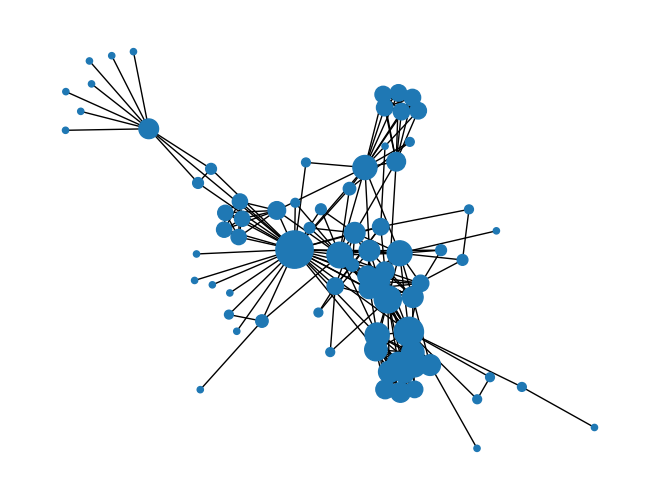

In [28]:
sizes = [degree[v] * 20 for v in G.nodes()]

# plt.figure(figsize=(6, 4))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=False, node_size=sizes)
plt.show()

Of course, with NetworkX's limited visualization options, a degree histogram is more informative. 

<BarContainer object of 37 artists>

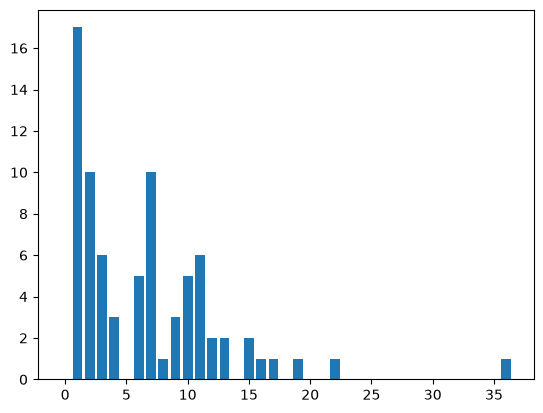

In [29]:
counts = nx.degree_histogram(G)
bins = range(len(counts))
plt.bar(bins, counts)

What does this tell us about the graph?

**Answer:** The degree distribution is very uneven. Many characters co-occur with only one or two others. A handful have very high degree: Valjean has 36, and Gavroche (22), Marius (19), Javert (17), Thenardier (16) and Fantine (15) all have degree 15 or more. These **hub** characters form the backbone of the network and connect the separate storylines. The many low-degree characters appear in a single scene with one main character. The values around 6–12 come from groups that always appear together, for example the revolutionary students around Enjolras.

### Other analysis
NetworkX contains most classical graph algorithms if they are needed for preprocessing.

In [30]:
# G is the Les Miserables graph here, so use two of its characters
print(nx.shortest_path(G, "Myriel", "Marius"))
print("Length:", nx.shortest_path_length(G, "Myriel", "Marius"))

['Myriel', 'Valjean', 'Marius']
Length: 2


## Reading and writing data
Unfortunately, there is still no standard format for network data. Fortunately, NetworkX can read most of them you come across in practice. 

In [31]:
G = nx.read_gml("lesmis.gml")

Typically, you will write to a format you need the data in, or otherwise most convienient. JSON is a nice, human readable format.

In [32]:
import json
jsdata = nx.node_link_data(G)
with open("jsdata.json", 'w') as fdata:
    json.dump(jsdata,fdata,indent=4)


## Working from tabular data 

A common workflow:
1. You have a table of edges (`source`, `target`, maybe `weight`)
2. Convert it into a graph


In [33]:
edges_df = pd.DataFrame({
    "source": ["A", "A", "B", "C", "D"],
    "target": ["B", "C", "C", "D", "A"],
    "weight": [3, 1, 2, 4, 5]
})
edges_df

,source,target,weight
0,A,B,3
1,A,C,1
2,B,C,2
3,C,D,4
4,D,A,5


Edges with data:
[('A', 'B', {'weight': 3}), ('A', 'C', {'weight': 1}), ('A', 'D', {'weight': 5}), ('B', 'C', {'weight': 2}), ('C', 'D', {'weight': 4})]


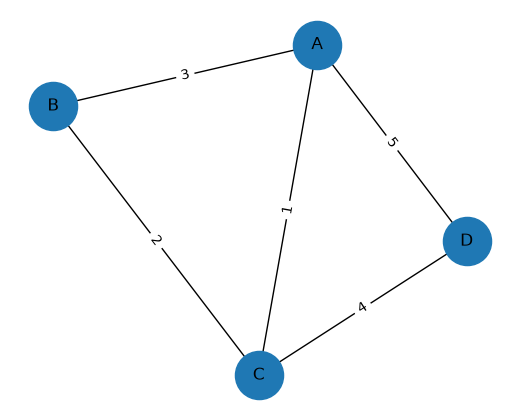

In [34]:
H = nx.from_pandas_edgelist(edges_df, source="source", target="target", edge_attr=True, create_using=nx.Graph())

print("Edges with data:")
print(list(H.edges(data=True)))

plt.figure(figsize=(5, 4))
pos = nx.spring_layout(H, seed=1)
nx.draw(H, pos, with_labels=True, node_size=1200)
nx.draw_networkx_edge_labels(H, pos, edge_labels=nx.get_edge_attributes(H, "weight"))
plt.show()

# Task 3: Real data
Of course, real data is likely not nicely specified with a "source" and "target" attribute. 

Included in this directory is `imdb_top250.csv` (provided file: `imdb_top100.csv`), which is a dataset that consists of the 250 highest ranked movies from IMDB. Several graphs could be derived from this data, but a natural one is described as follows: 
- Every movie defines a vertex 
- Two movies share an edge if they also share a costar (i.e. an overlap in their actor list).

Constructing a graph in this fashion is closer to an art than a science. We want to do it in a consistent, but parameterized way so that we can threshold and filter the data to obtain an ''analyzable'' output. Therefore your task is to write a function which 
- Constructs the graph described above
- Has a parameter, $k$, for which an edge is only added between movies if they share $k$ costars
- Has a parameter, `num_stars`, which controls how many of the actors/actresses in the list are looked at (they are listed in order of credits).

Afterwards, perform the basic analysis of visualization and analyzing degree distributions described earlier. What is the structure of the graph? Are there different components? Are there hub vertices? Save the graph to file for later use. 

In [35]:
from collections import defaultdict, Counter

df = pd.read_csv("imdb_top100.csv")
print(df.shape, "| movies without cast info:", df["actors_top10"].isna().sum())
df[["primaryTitle", "startYear", "actors_top10"]].head()

(100, 8) | movies without cast info: 2


,primaryTitle,startYear,actors_top10
0,The Shawshank Redemption,1994,"Tim Robbins, Morgan Freeman, Bob Gunton, Willi..."
1,The Godfather,1972,"Marlon Brando, Al Pacino, James Caan, Diane Ke..."
2,The Dark Knight,2008,"Christian Bale, Heath Ledger, Aaron Eckhart, M..."
3,The Lord of the Rings: The Return of the King,2003,"Elijah Wood, Viggo Mortensen, Ian McKellen, Or..."
4,Schindler's List,1993,"Liam Neeson, Ralph Fiennes, Ben Kingsley, Caro..."


In [36]:
def movie_costar_graph(df, k=1, num_stars=10):
    """Movies are vertices; an edge joins two movies that share >= k actors among the
    first `num_stars` credited actors of each movie.

    Implementation: build an actor -> movies index, then count for every movie pair
    how many actors they share (only pairs that share at least one actor are visited).
    """
    G = nx.Graph()
    actor_index = defaultdict(list)

    for _, row in df.iterrows():
        G.add_node(row["tconst"], title=row["primaryTitle"], year=int(row["startYear"]),
                   rating=float(row["averageRating"]))
        cast = row["actors_top10"]
        if isinstance(cast, str):
            for actor in [a.strip() for a in cast.split(",")][:num_stars]:
                actor_index[actor].append(row["tconst"])

    shared = Counter()
    who = defaultdict(list)
    for actor, movies in actor_index.items():
        for u, v in combinations(sorted(set(movies)), 2):
            shared[(u, v)] += 1
            who[(u, v)].append(actor)

    for (u, v), cnt in shared.items():
        if cnt >= k:
            G.add_edge(u, v, weight=cnt, shared_actors="; ".join(who[(u, v)]))
    return G


def describe(G):
    comps = [len(c) for c in nx.connected_components(G)]
    return dict(edges=G.number_of_edges(), components=len(comps), largest=max(comps),
                isolated=nx.number_of_isolates(G), avg_degree=round(2 * G.number_of_edges() / G.number_of_nodes(), 2))


grid = [dict(k=k, num_stars=s, **describe(movie_costar_graph(df, k, s)))
        for k in (1, 2, 3) for s in (3, 5, 10)]
pd.DataFrame(grid)

,k,num_stars,edges,components,largest,isolated,avg_degree
0,1,3,59,58,10,42,1.18
1,1,5,71,48,33,35,1.42
2,1,10,104,34,54,25,2.08
3,2,3,8,94,3,90,0.16
4,2,5,12,90,3,82,0.24
5,2,10,21,83,4,72,0.42
6,3,3,4,97,3,95,0.08
7,3,5,7,95,3,92,0.14
8,3,10,13,89,3,81,0.26


**Effect of the parameters.** The graph is very sensitive to both parameters:
- `k` (the number of shared actors needed for an edge) is the strongest filter. With `k = 1` and all 10 actors there are 104 edges. With `k = 2` only 21 remain, and with `k = 3` only 13. For `k ≥ 2`, almost the only edges left are **sequels or films from the same franchise**.
- `num_stars` matters less but in the same direction. If we only look at the top 3 credited actors, edges come only from lead actors (59 edges for `k = 1`). Including supporting actors connects many more movies, and the largest component grows from 10 to 54 movies.

For the analysis below we use `k = 1, num_stars = 10`. This is the only setting where a large connected structure appears at all.

{'edges': 104, 'components': 34, 'largest': 54, 'isolated': 25, 'avg_degree': 2.08}


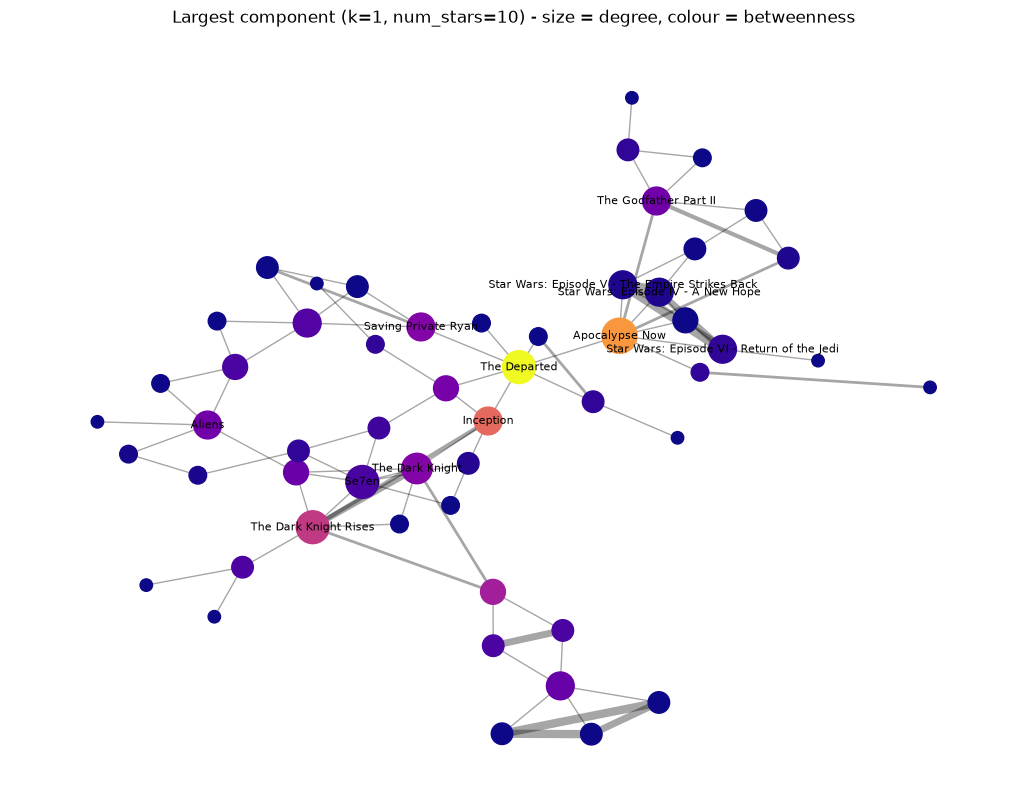

In [37]:
IMDB = movie_costar_graph(df, k=1, num_stars=10)
title = nx.get_node_attributes(IMDB, "title")
print(describe(IMDB))

giant = IMDB.subgraph(max(nx.connected_components(IMDB), key=len)).copy()
deg = dict(IMDB.degree)
btw = nx.betweenness_centrality(giant)

fig, ax = plt.subplots(figsize=(13, 10))
pos = nx.kamada_kawai_layout(giant)
nx.draw_networkx_edges(giant, pos, ax=ax, alpha=0.35, width=[w for *_, w in giant.edges(data="weight")])
nx.draw_networkx_nodes(giant, pos, ax=ax, node_size=[80 * deg[v] for v in giant],
                       node_color=[btw[v] for v in giant], cmap="plasma")
top = sorted(giant, key=lambda v: -deg[v])[:12]
nx.draw_networkx_labels(giant, pos, {v: title[v] for v in top}, font_size=8, ax=ax)
ax.set_title("Largest component (k=1, num_stars=10) - size = degree, colour = betweenness")
ax.axis("off")
plt.show()

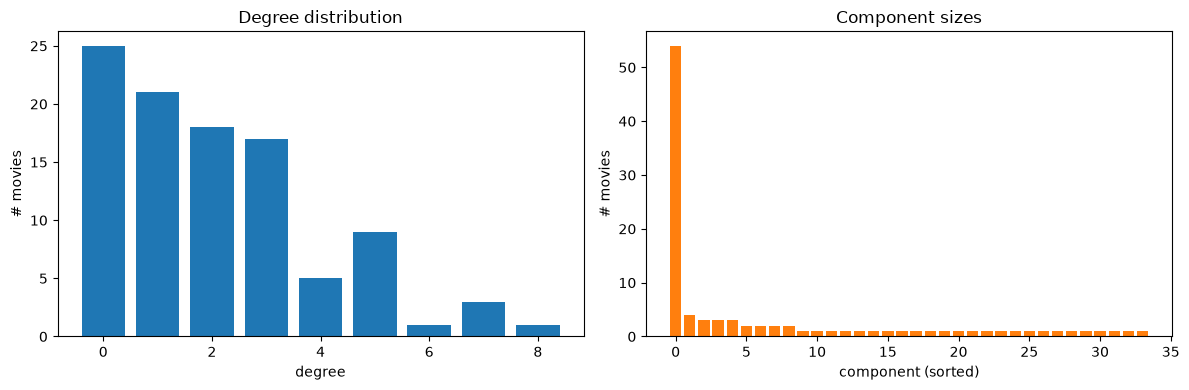

Highest degree:
  8  Apocalypse Now
  7  Se7en
  7  The Departed
  7  The Dark Knight Rises
  6  The Dark Knight
  5  The Godfather Part II
Highest betweenness (bridges inside the giant component):
  0.57  The Departed
  0.43  Apocalypse Now
  0.35  Inception
  0.26  The Dark Knight Rises
  0.20  The Prestige
  0.15  The Dark Knight
Heaviest edges:
  8  Star Wars: Episode V - The Empire Strikes Back -- Star Wars: Episode IV - A New Hope
  7  Star Wars: Episode V - The Empire Strikes Back -- Star Wars: Episode VI - Return of the Jedi
  6  The Lord of the Rings: The Return of the King -- The Lord of the Rings: The Fellowship of the Ring
  6  The Lord of the Rings: The Return of the King -- The Lord of the Rings: The Two Towers
  5  The Lord of the Rings: The Fellowship of the Ring -- The Lord of the Rings: The Two Towers
Isolated movies (sample): ["Schindler's List", 'The Good, the Bad and the Ugly', '12th Fail', 'The Silence of the Lambs', 'City of God', 'Life Is Beautiful', 'Back to th

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
hist = nx.degree_histogram(IMDB)
ax[0].bar(range(len(hist)), hist, color="tab:blue")
ax[0].set(xlabel="degree", ylabel="# movies", title="Degree distribution")
sizes = sorted((len(c) for c in nx.connected_components(IMDB)), reverse=True)
ax[1].bar(range(len(sizes)), sizes, color="tab:orange")
ax[1].set(xlabel="component (sorted)", ylabel="# movies", title="Component sizes")
plt.tight_layout()
plt.show()

print("Highest degree:")
for v in sorted(IMDB, key=lambda v: -deg[v])[:6]:
    print(f"  {deg[v]}  {title[v]}")
print("Highest betweenness (bridges inside the giant component):")
for v in sorted(btw, key=lambda v: -btw[v])[:6]:
    print(f"  {btw[v]:.2f}  {title[v]}")
print("Heaviest edges:")
for u, v, d in sorted(IMDB.edges(data=True), key=lambda e: -e[2]["weight"])[:5]:
    print(f"  {d['weight']}  {title[u]} -- {title[v]}")
print("Isolated movies (sample):", [title[v] for v in nx.isolates(IMDB)][:10])

**Answer (Task 3).**

*Components.* The graph is **not connected**. It has 34 components:
- a **giant component of 54 movies**;
- 8 small components with 2–4 movies each, typically trilogies or films that share a lead actor;
- **25 isolated movies**. Many of them are non-Hollywood productions or older classics whose casts do not overlap with any other top-100 movie, for example *Parasite, City of God, 12th Fail, The Intouchables, Life Is Beautiful, Schindler's List*.

*Degree distribution.* The distribution is strongly right-skewed. Most movies have degree 0–2 (average 2.08), and only a few reach 5–8. There is no single dominating hub, but there are several "connector" movies:
- **Apocalypse Now** (degree 8) links the *Godfather* films (Brando, Duvall) with *Star Wars* and *Raiders* (Harrison Ford).
- **Se7en**, **The Departed** and **The Dark Knight Rises** (degree 7) connect through Morgan Freeman, Brad Pitt, Kevin Spacey, Michael Caine, etc.

*Bridges.* Betweenness centrality shows which movies hold the giant component together. **The Departed** (0.57), **Apocalypse Now** (0.43) and **Inception** (0.35) sit between the "1970s / Star Wars / Godfather" cluster and the "Nolan / 1990s–2000s" cluster. The Departed and Apocalypse Now are even articulation points: removing either one splits the giant component (e.g. without The Departed it falls apart into pieces of 35, 15 and 3 movies). Inception, in contrast, is not a cut vertex. It lies on many shortest paths, but the component stays connected without it.

*Edge weights.* The heaviest edges are franchises: *Star Wars IV–V* share 8 actors, and the *Lord of the Rings* films share 5–6. These form small, tightly connected triangles.

**Overall structure:** a sparse network with one giant component and many isolated movies. It consists of local clusters (franchises, director/actor collaborations) that are connected through a few prolific actors, and therefore through a few bridge movies.

In [39]:
# save for later exercises
nx.write_gml(IMDB, "imdb_costar_k1_s10.gml")
nx.write_graphml(IMDB, "imdb_costar_k1_s10.graphml")
print("saved:", IMDB)

saved: Graph with 100 nodes and 104 edges
